# 🧠 Naive Bayes Classification Worksheet
*Titanic Survival Prediction — Categorical Naive Bayes*

---

Welcome! In this worksheet you will build a **complete Naive Bayes pipeline** on the Titanic dataset using only **categorical/discrete features**. This keeps the math simple and lets you focus on understanding the core algorithm.

> 💡 **How to use this worksheet**
> - Read each markdown cell — it explains **what** and **why**
> - Fill in every `# YOUR CODE HERE` block
> - Hints are provided in each task — use them!
> - Run cells in order from top to bottom

---

## 📋 Pipeline Steps
1. Data Loading & Exploration
2. Feature Selection & Preprocessing
3. Train-Test Split
4. Naive Bayes **from Scratch** (using frequency counts & probabilities)
5. Naive Bayes using **scikit-learn** (`CategoricalNB`)
6. Model Comparison & Evaluation


## 🛳️ Dataset Overview: Titanic

The Titanic dataset contains passenger information. Our goal is to **predict survival** (`Survived = 1` or `Survived = 0`).

### 📊 Features we will use (all discrete/categorical)

| Column | Values | Type |
|--------|--------|------|
| `Pclass` | 1, 2, 3 | Ordinal |
| `Sex` | male, female | Nominal |
| `Embarked` | C, Q, S | Nominal |
| `SibSp` | 0, 1, 2, … | Discrete |
| `Parch` | 0, 1, 2, … | Discrete |

> ✅ We intentionally **skip continuous features** like `Age` and `Fare` here. Simple (categorical) Naive Bayes works purely with **frequency counts** — no Gaussian distributions needed!


## Step 1: Data Loading & Exploration

### 📌 What to do:
- Import `pandas`, `numpy`, `matplotlib.pyplot`, and `seaborn`
- Load the CSV from the URL into a DataFrame called `data`
- Display the **first 5 rows**

> 💡 **Hint:** `pd.read_csv(url)` loads remote CSV files directly into a DataFrame.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

# YOUR CODE HERE
# 1. Load the dataset into 'data'
data = pd.read_csv(url)

# 2. Display the first 5 rows
display(data.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 🔎 Explore the Data

Check data types, missing values, and the distribution of the target column.

> 💡 **Hint:** Use `data.info()`, `data.isnull().sum()`, and `sns.countplot()`.



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values Per Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin      

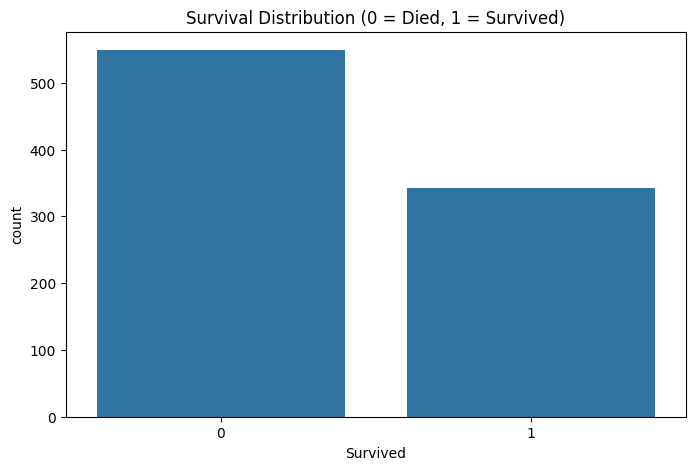

In [2]:
# YOUR CODE HERE
# 1. Print data.info() to see column types and null counts
print("\nDataset Info:")
data.info()

# 2. Print missing values per column
print("\nMissing Values Per Column:")
print(data.isnull().sum())

# 3. Plot a count plot of the 'Survived' column
plt.figure(figsize=(8,5))
sns.countplot(x='Survived', data=data)
plt.title("Survival Distribution (0 = Died, 1 = Survived)")
plt.show()

## Step 2: Feature Selection & Preprocessing

We will keep only the **5 categorical/discrete features** listed in the overview, plus the target column `Survived`.

### 📌 What to do:
**A) Select columns:** Keep only `Pclass`, `Sex`, `Embarked`, `SibSp`, `Parch`, and `Survived`.

**B) Handle missing values:**
- `Embarked` has 2 missing values → fill with the **most frequent** value (mode)

**C) Encode text columns:**
- `Sex`: `female` → 0, `male` → 1
- `Embarked`: `C` → 0, `Q` → 1, `S` → 2

> 💡 **Hint for (B):** `data['Embarked'].mode()[0]` gives the most frequent value. Use `.fillna()` to fill missing entries.

> 💡 **Hint for (C):** Use `LabelEncoder` from `sklearn.preprocessing`, or use a dictionary with `.map()` — either works.


In [3]:
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# A) Select only the relevant columns
cols = ['Pclass', 'Sex', 'Embarked', 'SibSp', 'Parch', 'Survived']
df = data[cols].dropna(subset=['Pclass', 'Sex', 'SibSp', 'Parch', 'Survived']).copy()

# B) Fill missing values in 'Embarked' with the most frequent value
df['Embarked'] = SimpleImputer(strategy='most_frequent').fit_transform(df[['Embarked']]).ravel()

# C) Encode 'Sex' and 'Embarked' as integers
le_sex = LabelEncoder()
le_embarked = LabelEncoder()

df['Sex'] = le_sex.fit_transform(df['Sex'])
df['Embarked'] = le_embarked.fit_transform(df['Embarked'])

# Confirm result
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df.head())


Shape: (891, 6)
Missing values: 0
   Pclass  Sex  Embarked  SibSp  Parch  Survived
0       3    1         2      1      0         0
1       1    0         0      1      0         1
2       3    0         2      0      0         1
3       1    0         2      1      0         1
4       3    1         2      0      0         0


## 📚 How Simple (Categorical) Naive Bayes Works

### 🔑 Core Idea

For a new passenger with features $X = (x_1, x_2, \dots, x_n)$, we want to find the class $y$ that maximises:

$$P(y \mid X) \propto P(y) \times \prod_{i=1}^{n} P(x_i \mid y)$$

We pick whichever class gives the **higher posterior probability**.

---

### 📐 The Three Quantities

| Quantity | Formula | How to compute |
|----------|---------|----------------|
| **Prior** $P(y)$ | $\frac{\text{count of class } y}{\text{total samples}}$ | Count rows per class |
| **Likelihood** $P(x_i \mid y)$ | $\frac{\text{count}(x_i, y)}{\text{count}(y)}$ | Count feature value within class |
| **Laplace Smoothing** | Add 1 to every count | Prevents zero probabilities |

---

### 🛡️ Why Laplace Smoothing?

If a feature value never appears with a class in training data, the raw probability is **zero**, which kills the entire product. Adding 1 to every count (and adjusting the denominator) avoids this.

$$P(x_i \mid y) = \frac{\text{count}(x_i, y) + 1}{\text{count}(y) + k}$$

where $k$ is the number of unique values of feature $x_i$.

---

### 💡 Example

Suppose we have 3 passengers:

| Pclass | Sex | Survived |
|--------|-----|----------|
| 3 | male | 0 |
| 1 | female | 1 |
| 3 | female | 1 |

For a new passenger: `Pclass=3, Sex=female`:

- $P(Survived=1) = 2/3$
- $P(Pclass=3 \mid Survived=1) = 1/2$
- $P(Sex=female \mid Survived=1) = 2/2 = 1$
- **Posterior(1)** ∝ $2/3 \times 1/2 \times 1 = 0.333$

Do the same for class 0, pick the higher one. ✅


## Step 3: Train-Test Split

Split the cleaned DataFrame into features `X` and target `y`, then into train/test sets.

### 📌 What to do:
- `X` = all columns except `Survived`
- `y` = the `Survived` column
- Use `train_test_split` with `test_size=0.2`, `random_state=42`, `stratify=y`
- Print the sizes of each split

> 💡 **Hint:** `stratify=y` ensures the same survival ratio in both splits.


In [4]:
from sklearn.model_selection import train_test_split

# 1. Define X and y using the clean 'df'
X = df.drop('Survived', axis=1)
y = df['Survived']
print("Input features")
print(X.head())
print("\nTarget/output y")
print(y.head())

# 2. Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTraining Samples: {len(X_train)}")
print(f"Testing Samples: {len(X_test)}")


Input features
   Pclass  Sex  Embarked  SibSp  Parch
0       3    1         2      1      0
1       1    0         0      1      0
2       3    0         2      0      0
3       1    0         2      1      0
4       3    1         2      0      0

Target/output y
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

Training Samples: 712
Testing Samples: 179


## Step 5: Naive Bayes with Scikit-learn 📦

Now use scikit-learn's `CategoricalNB`, which is designed exactly for discrete/categorical features.

### 📌 What to do:
- Import `CategoricalNB` from `sklearn.naive_bayes`
- Create the model and fit it on `X_train`, `y_train`
- Predict on `X_test` and store the result in `y_pred_lib`

> 💡 **Hint:** `CategoricalNB` expects non-negative integer inputs — your encoded features already satisfy this.

> 💡 **Laplace smoothing** is controlled by the `alpha` parameter (default = 1.0), which matches what you implemented from scratch.


In [5]:
from sklearn.naive_bayes import CategoricalNB

# YOUR CODE HERE
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 1. Create a CategoricalNB model (use default alpha=1.0)
model = CategoricalNB(alpha=1.0)

# 2. Fit on training data
model.fit(X_train, y_train)

# 3. Predict on test data, store in y_pred_lib
y_pred_lib = model.predict(X_test)


## Step 6: Model Comparison & Evaluation 📊

Evaluate both models using standard classification metrics.

### 📌 Metrics to compute:

| Metric | Meaning |
|--------|---------|
| **Accuracy** | % of total predictions that are correct |
| **Precision** | Of predicted survivors, how many actually survived |
| **Recall** | Of actual survivors, how many did we correctly identify |
| **F1-score** | Balanced measure of precision and recall |
| **Confusion Matrix** | TP / FP / TN / FN breakdown |

### 📌 What to do:
- Complete the `evaluate_model` function
- Call it once for the scratch model and once for the sklearn model
- Compare the results

> 💡 **Hint:** Use `accuracy_score`, `classification_report`, `confusion_matrix` from `sklearn.metrics`.  
> For the heatmap: `sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Died','Survived'], yticklabels=['Died','Survived'])`



  Naive Bayes (Scikit-Learn)
Accuracy: 0.7821

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.83       110
           1       0.74      0.67      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.77       179
weighted avg       0.78      0.78      0.78       179



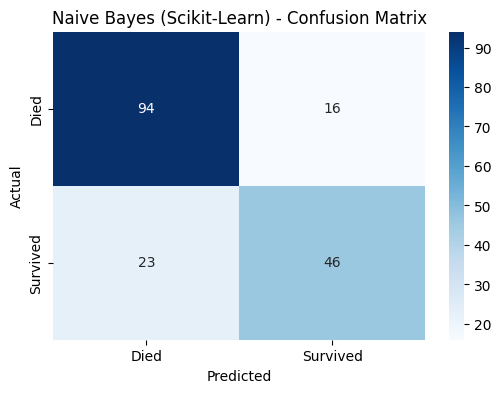

In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_model(name, y_true, y_pred):
    """
    Print accuracy + classification report and show a confusion matrix heatmap.
    """
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")

    # 1. Print accuracy_score
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}\n")

    # 2. Print classification_report
    print("Classification Report:")
    print(classification_report(y_true, y_pred))

    # 3. Compute confusion matrix and plot as heatmap
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Died', 'Survived'],
                yticklabels=['Died', 'Survived'])
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

evaluate_model("Naive Bayes (Scikit-Learn)", y_test, y_pred_lib)

In [ ]:
# Evaluate scratch implementation
evaluate_model("Categorical NB — From Scratch", y_test, y_pred_scratch)



  Categorical NB — Scikit-learn
Accuracy: 0.7821

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.83       110
           1       0.74      0.67      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.77       179
weighted avg       0.78      0.78      0.78       179



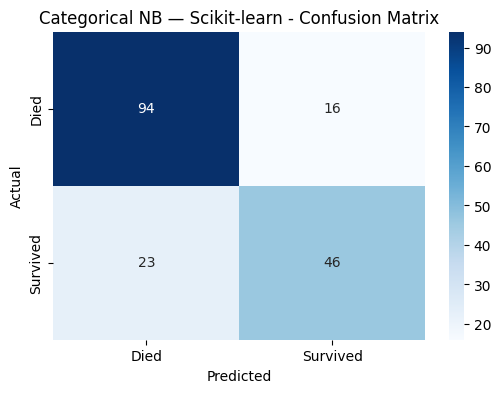

In [9]:
# Evaluate scikit-learn implementation
evaluate_model("Categorical NB — Scikit-learn", y_test, y_pred_lib)


## 🔍 Manual Probability Check (Optional but Highly Recommended!)

Pick **one specific passenger** from the test set and manually trace through the Naive Bayes calculation yourself to verify your model's prediction.

### 📌 What to do:
- Choose a row from `X_test` (e.g., the first row)
- Print its feature values
- Manually compute `P(Survived=1 | features)` and `P(Survived=0 | features)` step by step
- Check that your scratch model predicts the same class

> 💡 **Hint:** Use `X_test.iloc[0]` to get the first test row and `scratch_model._log_posterior(row)` to see the scores.
